In [1]:
# ===== Import các thư viện cần dùng =====
import warnings
import numpy as np                      # tính toán số học
import pandas as pd                     # xử lý bảng dữ liệu
import matplotlib.pyplot as plt         # vẽ biểu đồ
import seaborn as sns                   # biểu đồ thống kê đẹp hơn
from scipy import stats                 # các phép kiểm định thống kê (Shapiro, Chi-square, KS)
from sklearn.preprocessing import MinMaxScaler, StandardScaler   # chuẩn hóa dữ liệu
from sklearn.decomposition import PCA                            # giảm chiều dữ liệu

warnings.filterwarnings("ignore")       # ẩn cảnh báo cho gọn
sns.set_theme(style="whitegrid")        # giao diện nền lưới cho biểu đồ
%matplotlib inline
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")   # hiển thị số 3 chữ số thập phân

In [2]:
# ===== CẤU HÌNH: sửa cho đúng với dữ liệu của bạn =====
TRAIN_PATH = "train.csv"      # đường dẫn file train
TEST_PATH = "test.csv"        # đường dẫn file test
TARGET = "SalePrice"          # tên cột giá nhà (chỉ có trong train)
ID_COL = "Id"                 # cột mã định danh; nếu không có thì đặt None
DISCRETE_MAX_UNIQUE = 20      # cột số có <= 20 giá trị khác nhau sẽ coi là rời rạc (discrete)

In [3]:
# ===== Đọc dữ liệu =====
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Kích thước train:", train.shape)
print("Kích thước test :", test.shape)

# Test không có cột giá nhà (vì đó là thứ cần dự đoán). Kiểm tra lại cho chắc:
print("Cột có ở train nhưng không có ở test:", set(train.columns) - set(test.columns))

train.head()

Kích thước train: (1460, 81)
Kích thước test : (1459, 80)
Cột có ở train nhưng không có ở test: {'SalePrice'}


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,"2,003.000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,"1,976.000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,"2,001.000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,...,1,Gd,Detchd,"1,998.000",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,"2,000.000",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# ===== Tách cột thành 2 nhóm: số (numeric) và phân loại (categorical) =====
# Loại bỏ cột mục tiêu và cột Id vì chúng không phải đặc trưng (feature)
feature_cols = [c for c in train.columns if c not in [TARGET, ID_COL]]

# Cột có kiểu số -> numeric; còn lại -> categorical
num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(train[c])]
cat_cols = [c for c in feature_cols if c not in num_cols]

print(f"Số đặc trưng: {len(feature_cols)} (numeric: {len(num_cols)}, categorical: {len(cat_cols)})")

Số đặc trưng: 79 (numeric: 36, categorical: 43)


## 1. Xác định tính chất dữ liệu  

Theo Chương 2, cần xác định:
- **Dạng dữ liệu:** structured (bảng), unstructured hay semi-structured.
- **Loại thuộc tính:** categorical (nominal, ordinal) hay numeric (interval, ratio); rời rạc hay liên tục.
- **Số biến:** univariate (1 biến), bivariate (2 biến), multivariate (từ 3 biến trở lên).

In [5]:
# ===== Bảng tính chất của từng cột =====
rows = []
for c in feature_cols:
    s = train[c]
    if c in num_cols:
        # Cột số ít giá trị khác nhau -> rời rạc (vd: số phòng); nhiều -> liên tục (vd: diện tích)
        loai = "Numeric - rời rạc" if s.nunique() <= DISCRETE_MAX_UNIQUE else "Numeric - liên tục"
        thang_do = "Interval / Ratio"
    else:
        loai = "Categorical"
        thang_do = "Nominal / Ordinal"   # cần đọc mô tả cột để biết có thứ tự hay không
    rows.append({
        "feature": c,
        "dtype": str(s.dtype),
        "loại dữ liệu": loai,
        "thang đo": thang_do,
        "số giá trị khác nhau": s.nunique(),
        "ví dụ": s.dropna().iloc[0] if s.notna().any() else None,
    })

properties = pd.DataFrame(rows).set_index("feature")
properties

,dtype,loại dữ liệu,thang đo,số giá trị khác nhau,ví dụ
feature,,,,,
MSSubClass,int64,Numeric - rời rạc,Interval / Ratio,15,60
MSZoning,str,Categorical,Nominal / Ordinal,5,RL
LotFrontage,float64,Numeric - liên tục,Interval / Ratio,110,65.000
LotArea,int64,Numeric - liên tục,Interval / Ratio,1073,8450
Street,str,Categorical,Nominal / Ordinal,2,Pave
...,...,...,...,...,...
MiscVal,int64,Numeric - liên tục,Interval / Ratio,21,0
MoSold,int64,Numeric - rời rạc,Interval / Ratio,12,2
YrSold,int64,Numeric - rời rạc,Interval / Ratio,5,2008


In [6]:
# ===== Thống kê nhanh về tính chất tổng thể =====
print("Dạng dữ liệu       : structured data (dữ liệu bảng / record data)")
print("Số biến            : multivariate (nhiều hơn 2 biến)")
print(f"Số mẫu (dòng)      : {len(train)}")
print(f"Số dòng trùng lặp  : {train.duplicated().sum()}")
print()
print("Phân bố loại dữ liệu:")
print(properties["loại dữ liệu"].value_counts())

Dạng dữ liệu       : structured data (dữ liệu bảng / record data)
Số biến            : multivariate (nhiều hơn 2 biến)
Số mẫu (dòng)      : 1460
Số dòng trùng lặp  : 0

Phân bố loại dữ liệu:
loại dữ liệu
Categorical           43
Numeric - liên tục    20
Numeric - rời rạc     16
Name: count, dtype: int64


**Nhận xét (điền sau khi chạy):**
- Dữ liệu là dạng bảng (structured), gồm … biến numeric và … biến categorical.
- Các biến như `OverallQual` (thang 1–10) là *ordinal* dù được lưu bằng số; biến `Neighborhood` là *nominal*.
- Biến mục tiêu `SalePrice` là numeric liên tục (ratio) → đây là bài toán **hồi quy**.

## 2. Phân tích đơn biến  

Với mỗi biến, mô tả bằng 4 nhóm đặc trưng:
1. **Phân phối tần số** (histogram, bar chart)
2. **Xu hướng trung tâm** (mean, median, mode)
3. **Độ phân tán** (range, variance, std, IQR, MAD, CV)
4. **Hình dạng** (skewness, kurtosis)

In [7]:
# ===== Hàm tính bảng thống kê mô tả cho nhiều cột số =====
def describe_numeric(df, cols):
    out = []
    for c in cols:
        s = df[c].dropna()                       # bỏ giá trị thiếu trước khi tính
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])        # tứ phân vị thứ nhất và thứ ba
        mode = s.mode()                          # mode: giá trị xuất hiện nhiều nhất
        out.append({
            "feature": c,
            "count": s.count(),
            "mean": s.mean(),                    # trung bình
            "median": s.median(),                # trung vị
            "mode": mode.iloc[0] if not mode.empty else np.nan,
            "min": s.min(),
            "Q1": q1,
            "Q3": q3,
            "max": s.max(),
            "range": s.max() - s.min(),          # khoảng biến thiên = max - min
            "IQR": q3 - q1,                      # khoảng tứ phân vị (Eq. 2.9)
            "variance": s.var(),                 # phương sai
            "std": s.std(),                      # độ lệch chuẩn (Eq. 2.8, chia N-1)
            "MAD": (s - s.mean()).abs().mean(),  # độ lệch tuyệt đối trung bình (Eq. 2.16)
            "CV(%)": s.std() / s.mean() * 100 if s.mean() != 0 else np.nan,  # hệ số biến thiên
            "skewness": s.skew(),                # độ lệch (Eq. 2.13)
            "kurtosis": s.kurt(),                # độ nhọn (Eq. 2.14)
        })
    return pd.DataFrame(out).set_index("feature")

### 2.1 Biến mục tiêu – giá nhà

In [8]:
# ===== Thống kê mô tả của giá nhà =====
describe_numeric(train, [TARGET]).T

feature,SalePrice
count,"1,460.000"
mean,"180,921.196"
median,"163,000.000"
mode,"140,000.000"
min,"34,900.000"
Q1,"129,975.000"
Q3,"214,000.000"
max,"755,000.000"
range,"720,100.000"
IQR,"84,025.000"


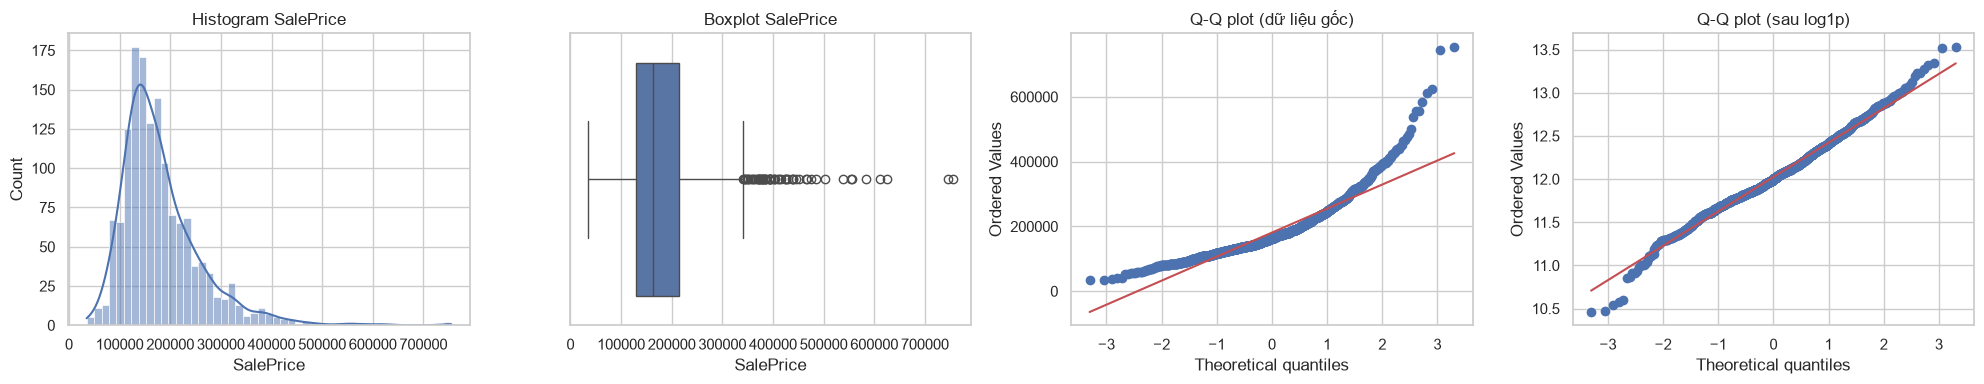

In [9]:
# ===== Vẽ 4 biểu đồ cho biến mục tiêu: histogram, boxplot, Q-Q plot (gốc và sau log) =====
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

sns.histplot(train[TARGET], kde=True, ax=axes[0])        # histogram + đường mật độ
axes[0].set_title(f"Histogram {TARGET}")

sns.boxplot(x=train[TARGET], ax=axes[1])                 # boxplot: thấy median, IQR và outlier
axes[1].set_title(f"Boxplot {TARGET}")

# Q-Q plot: nếu dữ liệu chuẩn thì các điểm nằm sát đường thẳng (Hình 2.10)
stats.probplot(train[TARGET].dropna(), dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot (dữ liệu gốc)")

# Biến đổi log1p = log(1 + x) để giảm độ lệch phải
stats.probplot(np.log1p(train[TARGET].dropna()), dist="norm", plot=axes[3])
axes[3].set_title("Q-Q plot (sau log1p)")

plt.tight_layout()
plt.show()

In [10]:
# ===== Kiểm tra độ lệch và tính chuẩn =====
sk = train[TARGET].skew()
print(f"Skewness của {TARGET}: {sk:.3f} -> {'lệch phải (positive skew)' if sk > 0 else 'lệch trái (negative skew)'}")
print(f"Mean = {train[TARGET].mean():,.0f} | Median = {train[TARGET].median():,.0f}")
print("Lệch phải thì mean > median (vài căn nhà rất đắt kéo trung bình lên).")
print(f"Skewness sau log1p: {np.log1p(train[TARGET]).skew():.3f}  (gần 0 nghĩa là gần đối xứng)")

# Kiểm định Shapiro-Wilk: H0 = dữ liệu có phân phối chuẩn. p < 0.05 -> bác bỏ H0
sample = train[TARGET].dropna().sample(min(5000, len(train)), random_state=0)
stat, p = stats.shapiro(sample)
print(f"\nShapiro-Wilk (dữ liệu gốc): p = {p:.4g} -> {'KHÔNG' if p < 0.05 else ''} phân phối chuẩn")
stat, p = stats.shapiro(np.log1p(sample))
print(f"Shapiro-Wilk (sau log1p)  : p = {p:.4g}")

Skewness của SalePrice: 1.883 -> lệch phải (positive skew)
Mean = 180,921 | Median = 163,000
Lệch phải thì mean > median (vài căn nhà rất đắt kéo trung bình lên).
Skewness sau log1p: 0.121  (gần 0 nghĩa là gần đối xứng)

Shapiro-Wilk (dữ liệu gốc): p = 3.206e-33 -> KHÔNG phân phối chuẩn
Shapiro-Wilk (sau log1p)  : p = 1.149e-07


**Nhận xét (điền sau khi chạy):** giá nhà lệch phải, có đuôi dài bên phải (nhà cao cấp). Sau khi log-transform, phân phối gần chuẩn hơn
→ nên dự đoán `log(SalePrice)` để mô hình hoạt động tốt hơn.

> Lưu ý: khi **positive skew** thì *mean > median*. (Một số đoạn trong sách diễn đạt chưa nhất quán chỗ này, bạn nên theo quy ước vừa nêu.)

### 2.2 Các biến numeric

In [11]:
# ===== Bảng thống kê mô tả cho tất cả biến numeric =====
stats_num = describe_numeric(train, num_cols)
stats_num

,count,mean,median,mode,min,Q1,Q3,max,range,IQR,variance,std,MAD,CV(%),skewness,kurtosis
feature,,,,,,,,,,,,,,,,
MSSubClass,1460,56.897,50.000,20.000,20.000,20.000,70.000,190.000,170.000,50.000,"1,789.338",42.301,31.283,74.346,1.408,1.580
LotFrontage,1201,70.050,69.000,60.000,21.000,59.000,80.000,313.000,292.000,21.000,589.749,24.285,16.762,34.668,2.164,17.453
LotArea,1460,"10,516.828","9,478.500","7,200.000","1,300.000","7,553.500","11,601.500","215,245.000","213,945.000","4,048.000","99,625,649.650","9,981.265","3,758.814",94.908,12.208,203.243
OverallQual,1460,6.099,6.000,5.000,1.000,5.000,7.000,10.000,9.000,2.000,1.913,1.383,1.098,22.675,0.217,0.096
OverallCond,1460,5.575,5.000,5.000,1.000,5.000,6.000,9.000,8.000,1.000,1.238,1.113,0.889,19.959,0.693,1.106
YearBuilt,1460,"1,971.268","1,973.000","2,006.000","1,872.000","1,954.000","2,000.000","2,010.000",138.000,46.000,912.215,30.203,25.067,1.532,-0.613,-0.440
YearRemodAdd,1460,"1,984.866","1,994.000","1,950.000","1,950.000","1,967.000","2,004.000","2,010.000",60.000,37.000,426.233,20.645,18.623,1.040,-0.504,-1.272
MasVnrArea,1452,103.685,0.000,0.000,0.000,0.000,166.000,"1,600.000","1,600.000",166.000,"32,784.971",181.066,129.782,174.631,2.669,10.082
BsmtFinSF1,1460,443.640,383.500,0.000,0.000,0.000,712.250,"5,644.000","5,644.000",712.250,"208,025.468",456.098,367.370,102.808,1.686,11.118


In [12]:
# ===== Top biến lệch nhiều nhất và biến có độ nhọn lớn nhất =====
print("Top 10 biến lệch nhất (|skewness| lớn):")
print(stats_num["skewness"].abs().sort_values(ascending=False).head(10))
print("\nTop 10 biến có kurtosis lớn nhất (đuôi nặng, nhiều outlier):")
print(stats_num["kurtosis"].sort_values(ascending=False).head(10))

Top 10 biến lệch nhất (|skewness| lớn):
feature
MiscVal         24.477
PoolArea        14.828
LotArea         12.208
3SsnPorch       10.304
LowQualFinSF     9.011
KitchenAbvGr     4.488
BsmtFinSF2       4.255
ScreenPorch      4.122
BsmtHalfBath     4.103
EnclosedPorch    3.090
Name: skewness, dtype: float64

Top 10 biến có kurtosis lớn nhất (đuôi nặng, nhiều outlier):
feature
MiscVal        701.003
PoolArea       223.268
LotArea        203.243
3SsnPorch      123.662
LowQualFinSF    83.235
KitchenAbvGr    21.532
BsmtFinSF2      20.113
ScreenPorch     18.439
LotFrontage     17.453
BsmtHalfBath    16.397
Name: kurtosis, dtype: float64


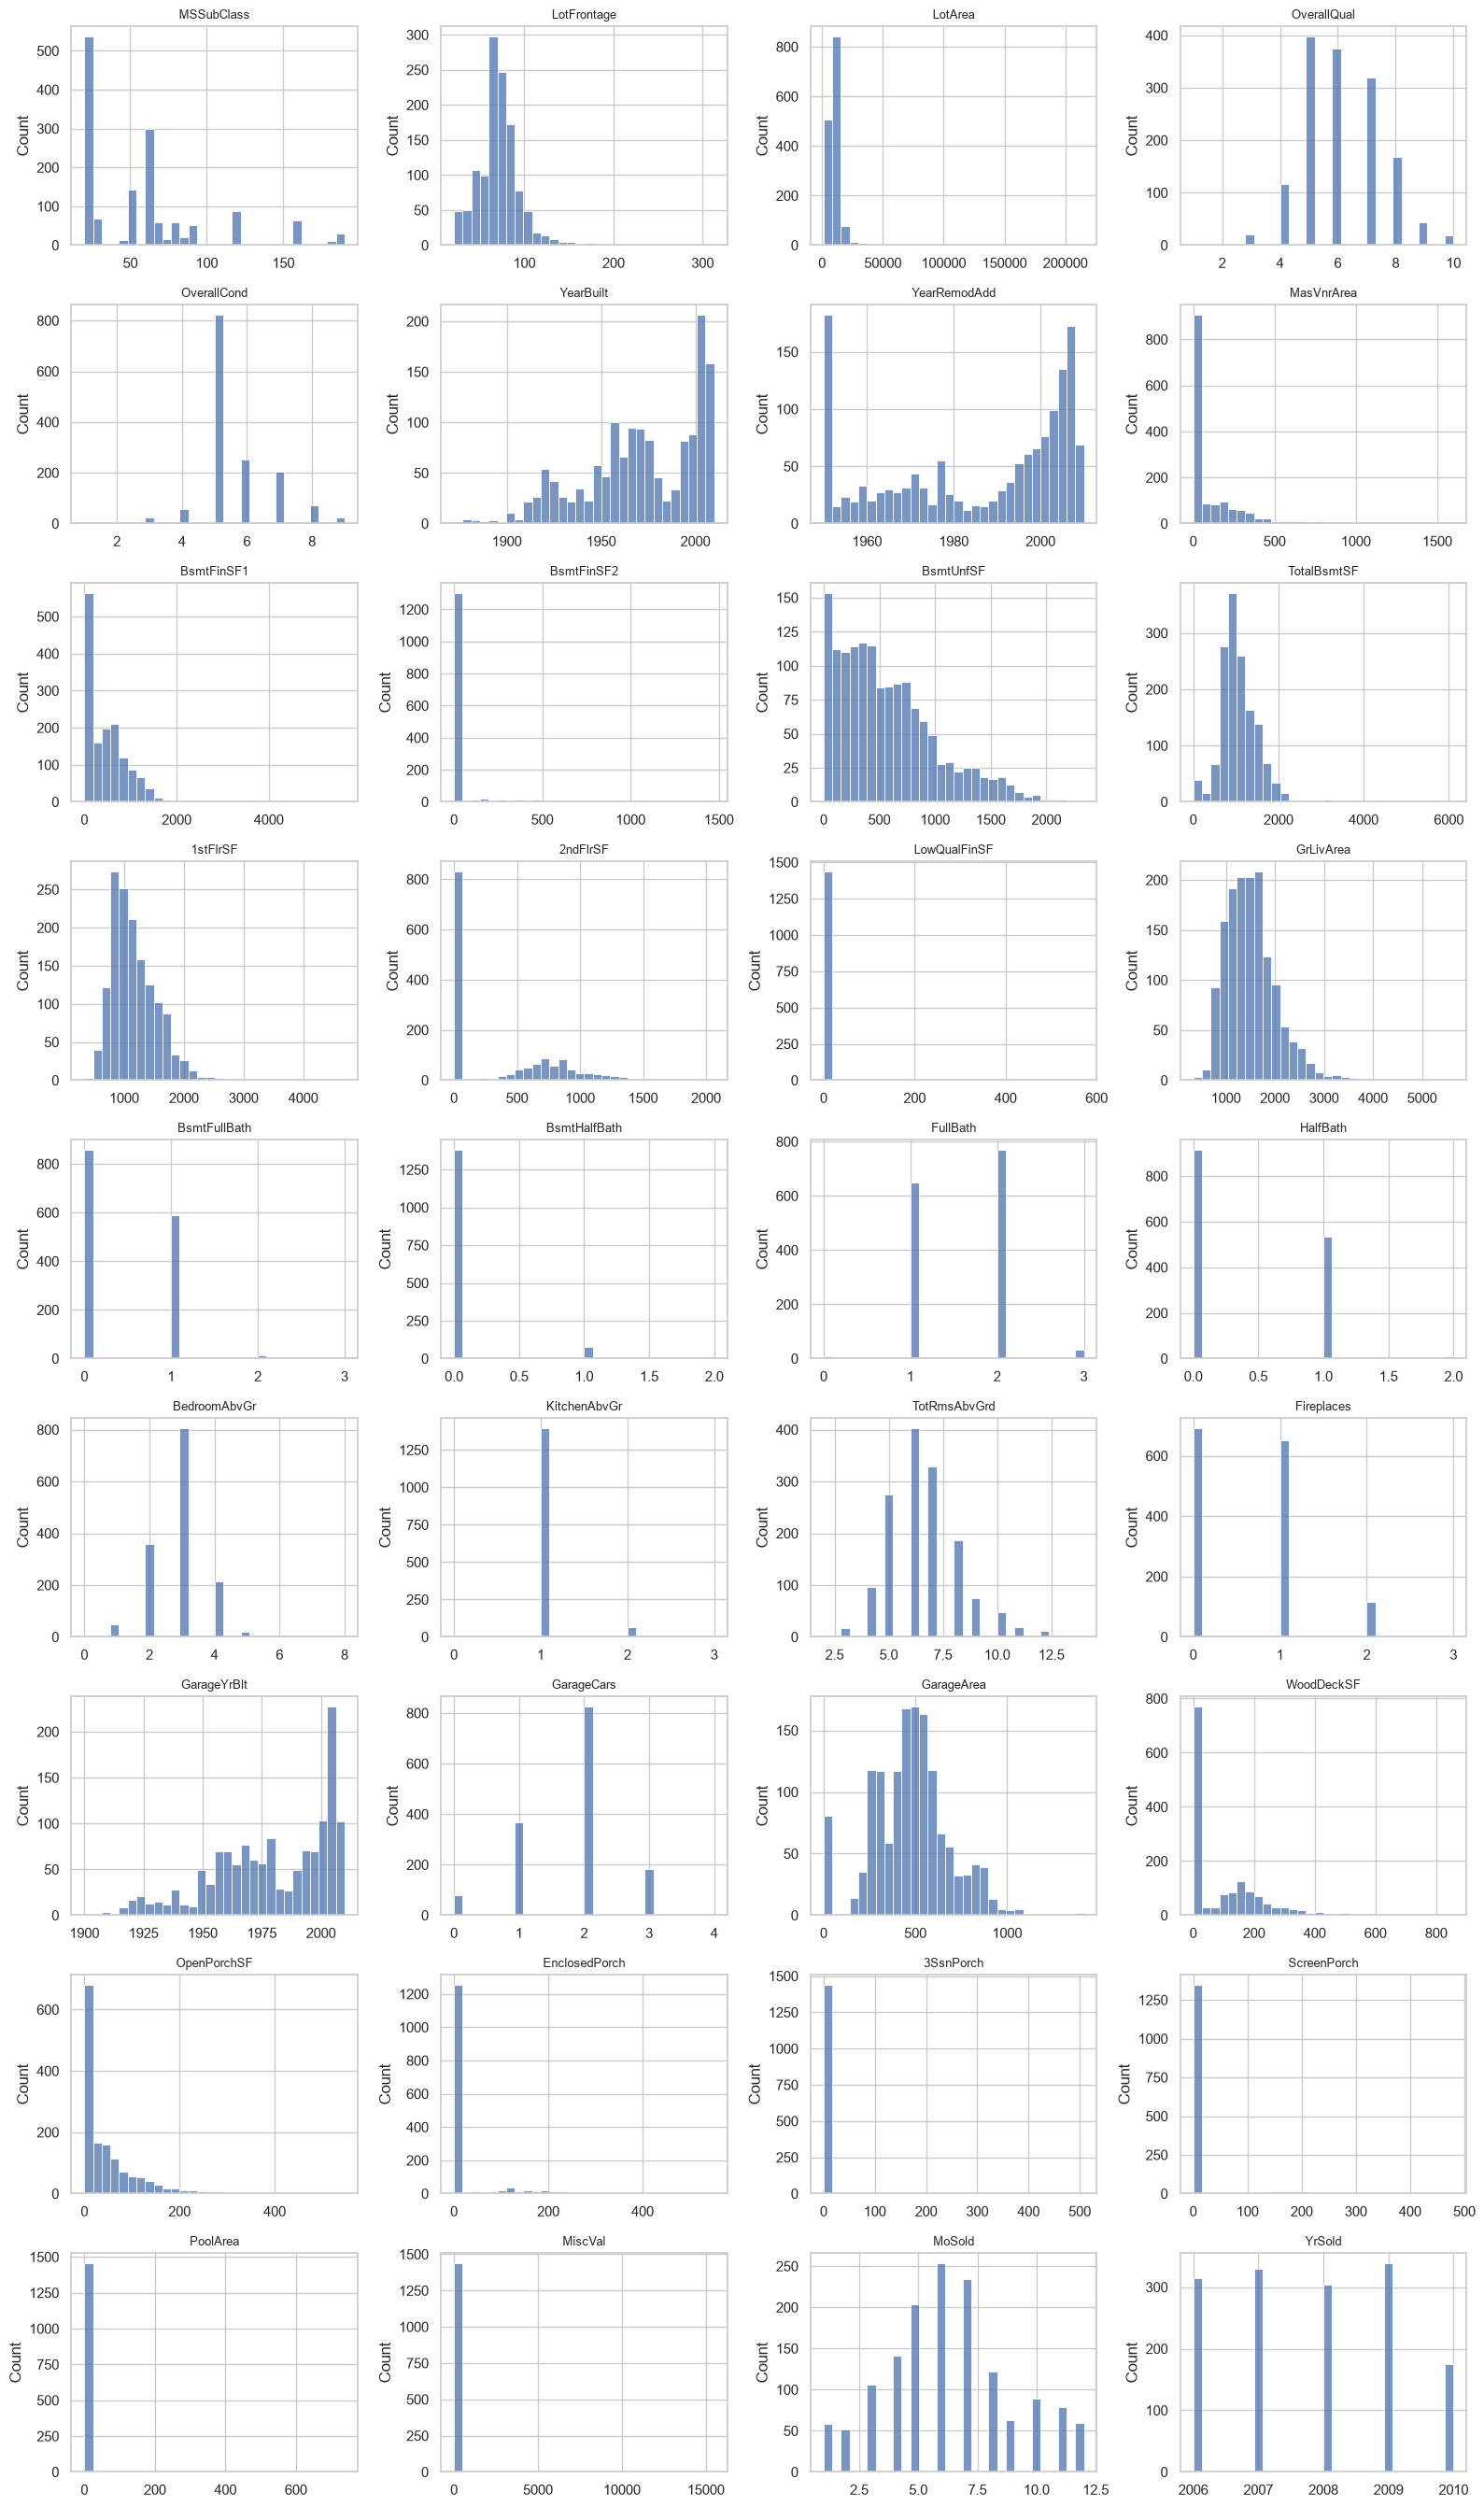

In [13]:
# ===== Histogram của tất cả biến numeric (lưới nhiều ô con) =====
n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, num_cols):
    sns.histplot(train[c].dropna(), bins=30, ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
for ax in axes[n:]:          # tắt các ô thừa
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.3 Các biến categorical

In [14]:
# ===== Thống kê biến categorical: số nhóm, mode và tỷ lệ của mode =====
cat_summary = []
for c in cat_cols:
    vc = train[c].value_counts(dropna=False)
    cat_summary.append({
        "feature": c,
        "số nhóm": train[c].nunique(),
        "mode": vc.index[0],                          # nhóm xuất hiện nhiều nhất
        "tỷ lệ mode (%)": vc.iloc[0] / len(train) * 100,
    })
cat_summary = pd.DataFrame(cat_summary).set_index("feature")
cat_summary.sort_values("tỷ lệ mode (%)", ascending=False)

,số nhóm,mode,tỷ lệ mode (%)
feature,,,
Utilities,2,AllPub,99.932
Street,2,Pave,99.589
PoolQC,3,NaN,99.521
Condition2,8,Norm,98.973
RoofMatl,8,CompShg,98.219
Heating,6,GasA,97.808
MiscFeature,4,NaN,96.301
LandSlope,3,Gtl,94.658
Alley,2,NaN,93.767


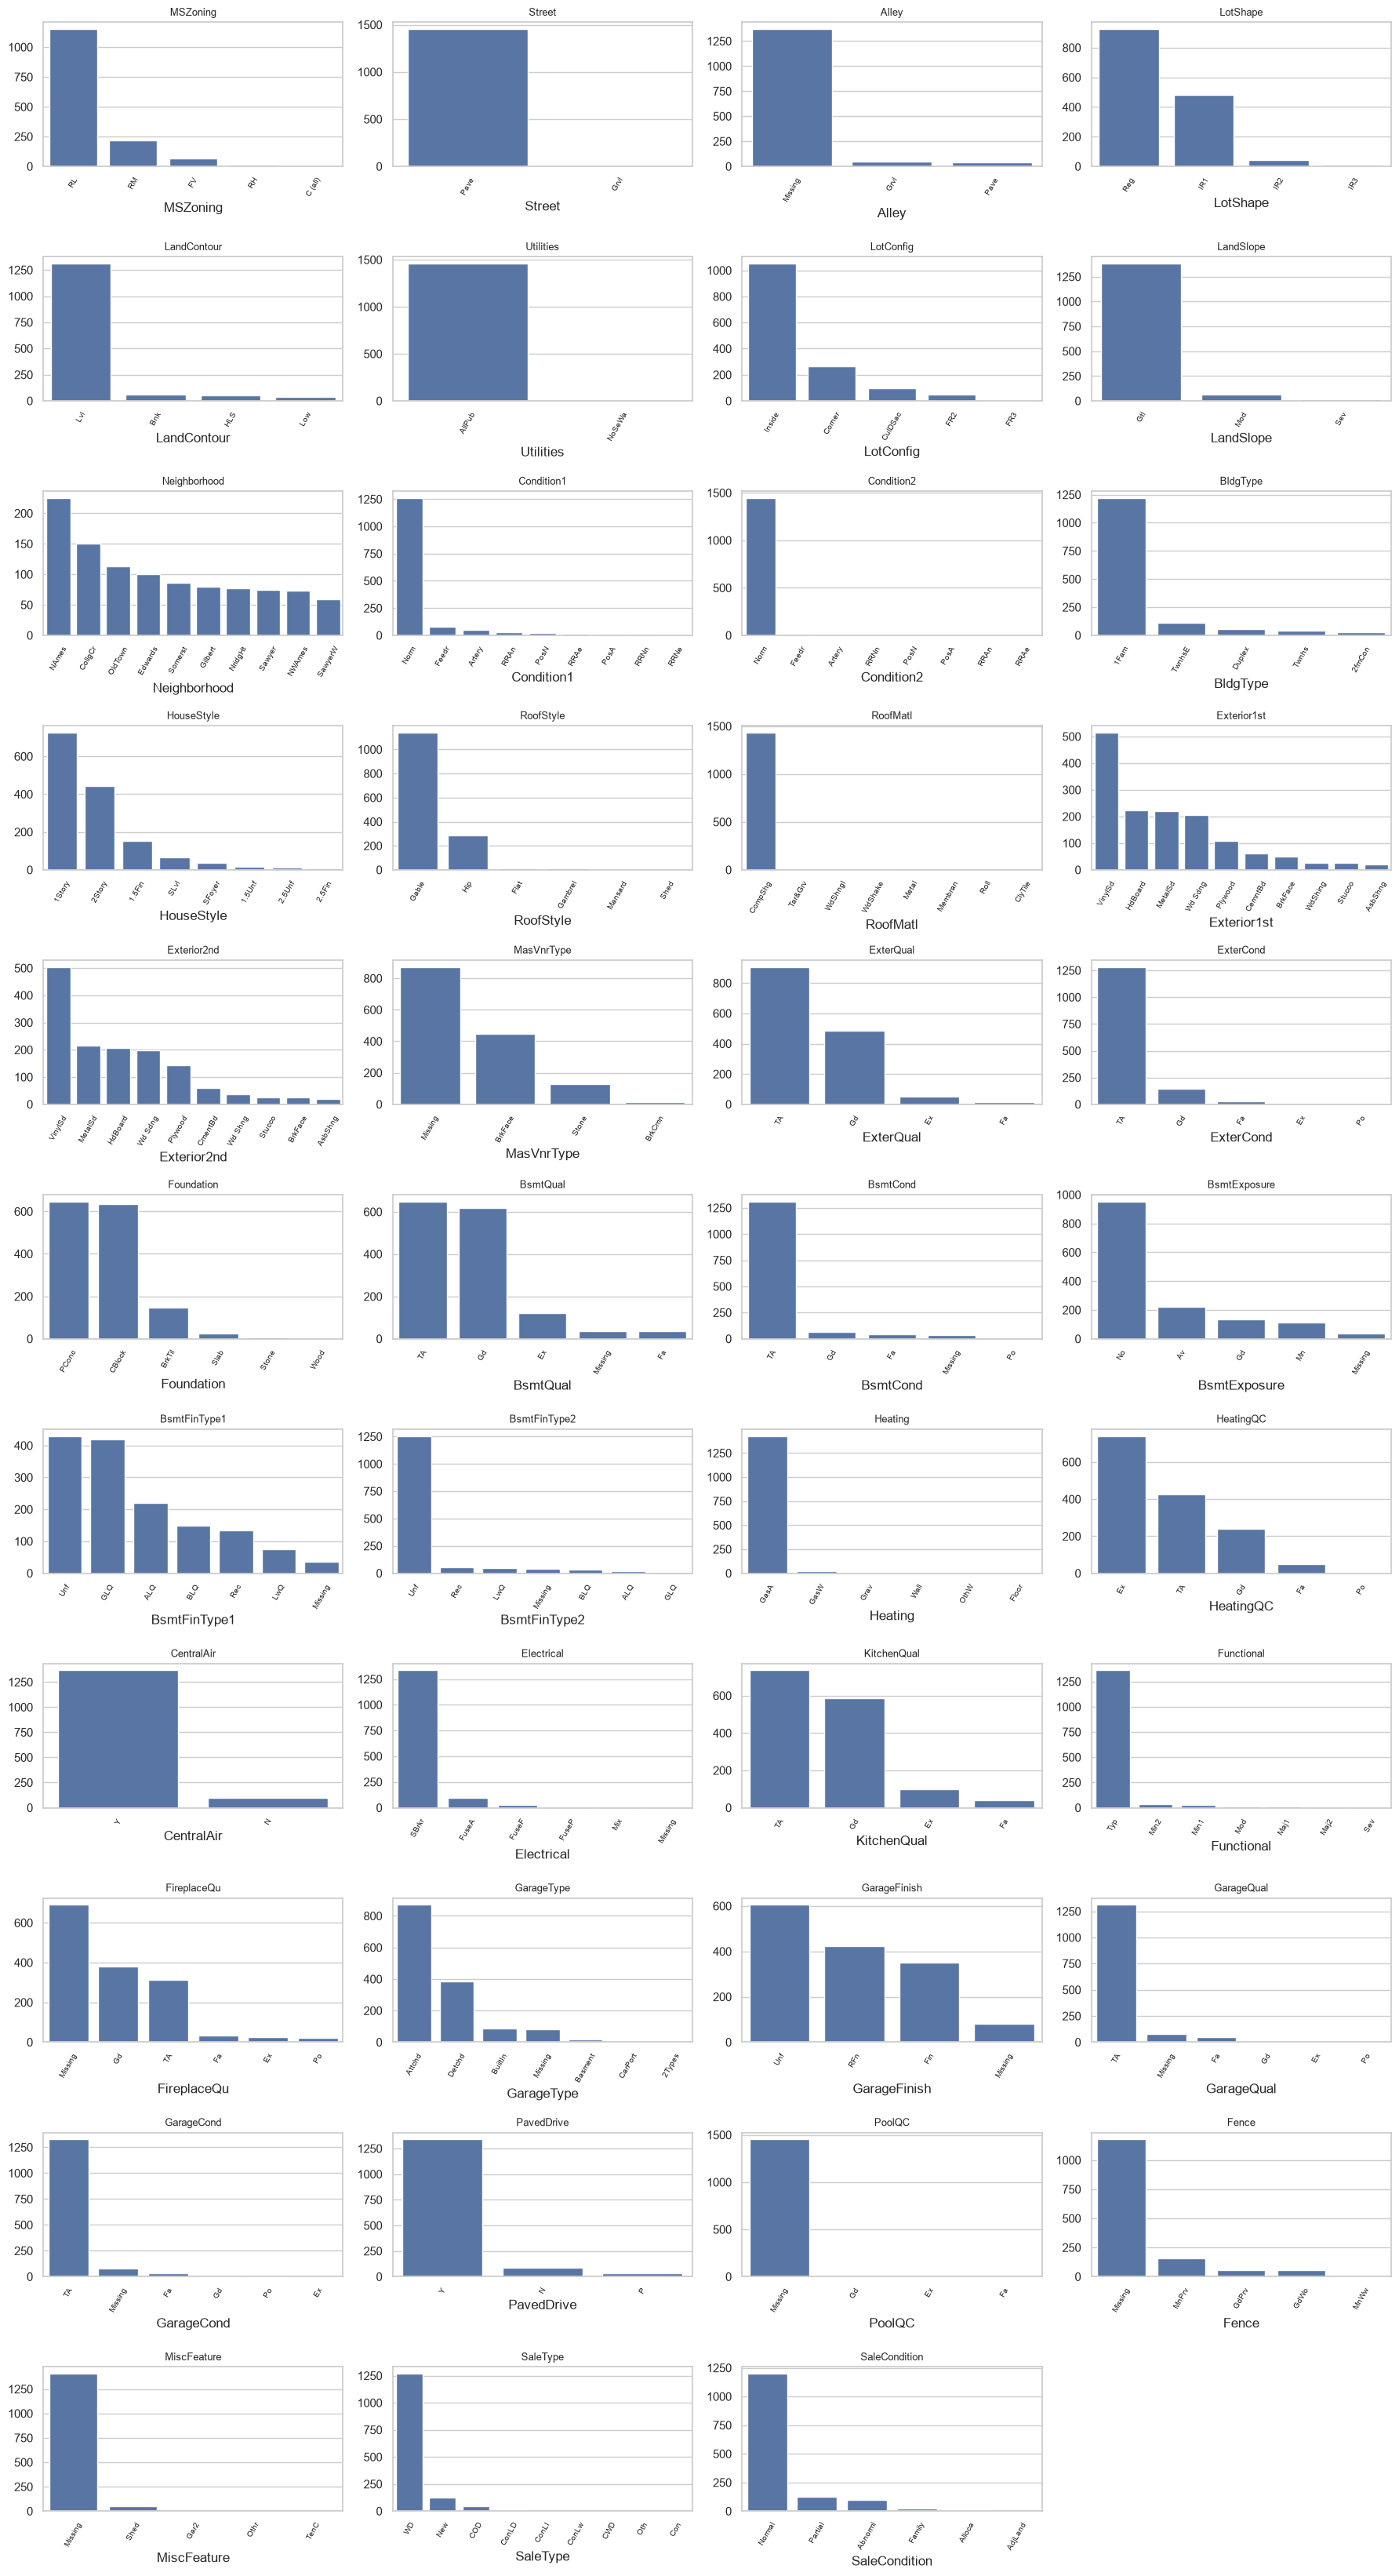

In [15]:
# ===== Bar chart tần số cho từng biến categorical (tối đa 10 nhóm phổ biến nhất) =====
if cat_cols:
    n = len(cat_cols)
    ncols = 4
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cat_cols):
        vc = train[c].fillna("Missing").value_counts().head(10)
        sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax)
        ax.set_title(c, fontsize=9)
        ax.tick_params(axis="x", rotation=60, labelsize=7)
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 3. Phân tích đa biến  

Mục tiêu: tìm **mối quan hệ** giữa các biến với giá nhà, và giữa các biến với nhau
(để phát hiện biến dư thừa – *redundant*).
Công cụ: covariance, hệ số tương quan Pearson , heatmap, scatter plot, pairplot, Chi-square.

### 3.1 Tương quan giữa các biến numeric và giá nhà

In [16]:
# ===== Tương quan Pearson của từng biến numeric với giá nhà =====
# r > 0: cùng tăng; r < 0: một biến tăng thì biến kia giảm; r ~ 0: không có quan hệ tuyến tính
corr_all = train[num_cols + [TARGET]].corr()
corr_target = corr_all[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

print("Top 15 biến tương quan mạnh nhất với", TARGET)
corr_target.head(15).to_frame("Pearson r")

Top 15 biến tương quan mạnh nhất với SalePrice


,Pearson r
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


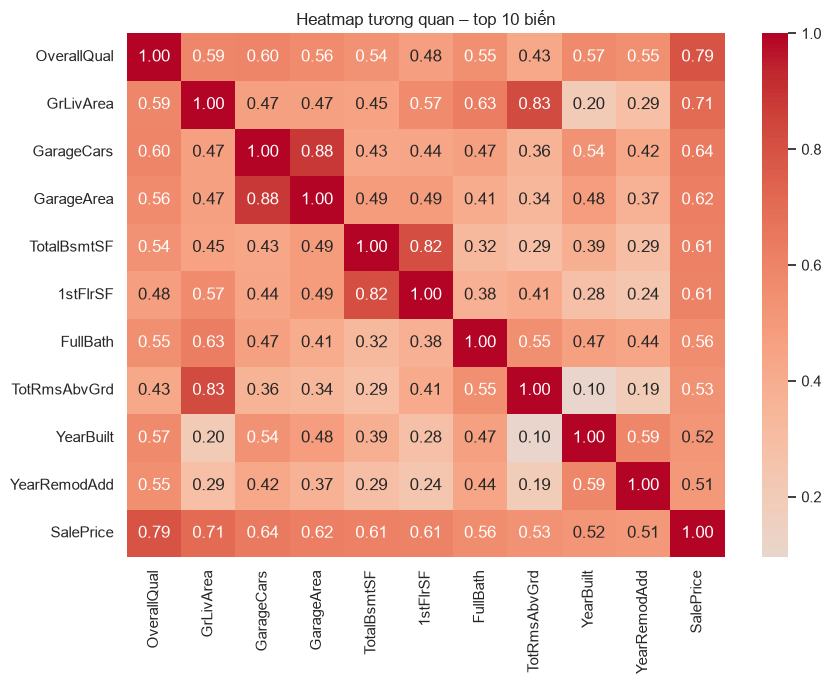

In [17]:
# ===== Heatmap tương quan của 10 biến mạnh nhất =====
top_k = corr_target.head(10).index.tolist()

plt.figure(figsize=(9, 7))
sns.heatmap(train[top_k + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap tương quan – top 10 biến")
plt.tight_layout()
plt.show()

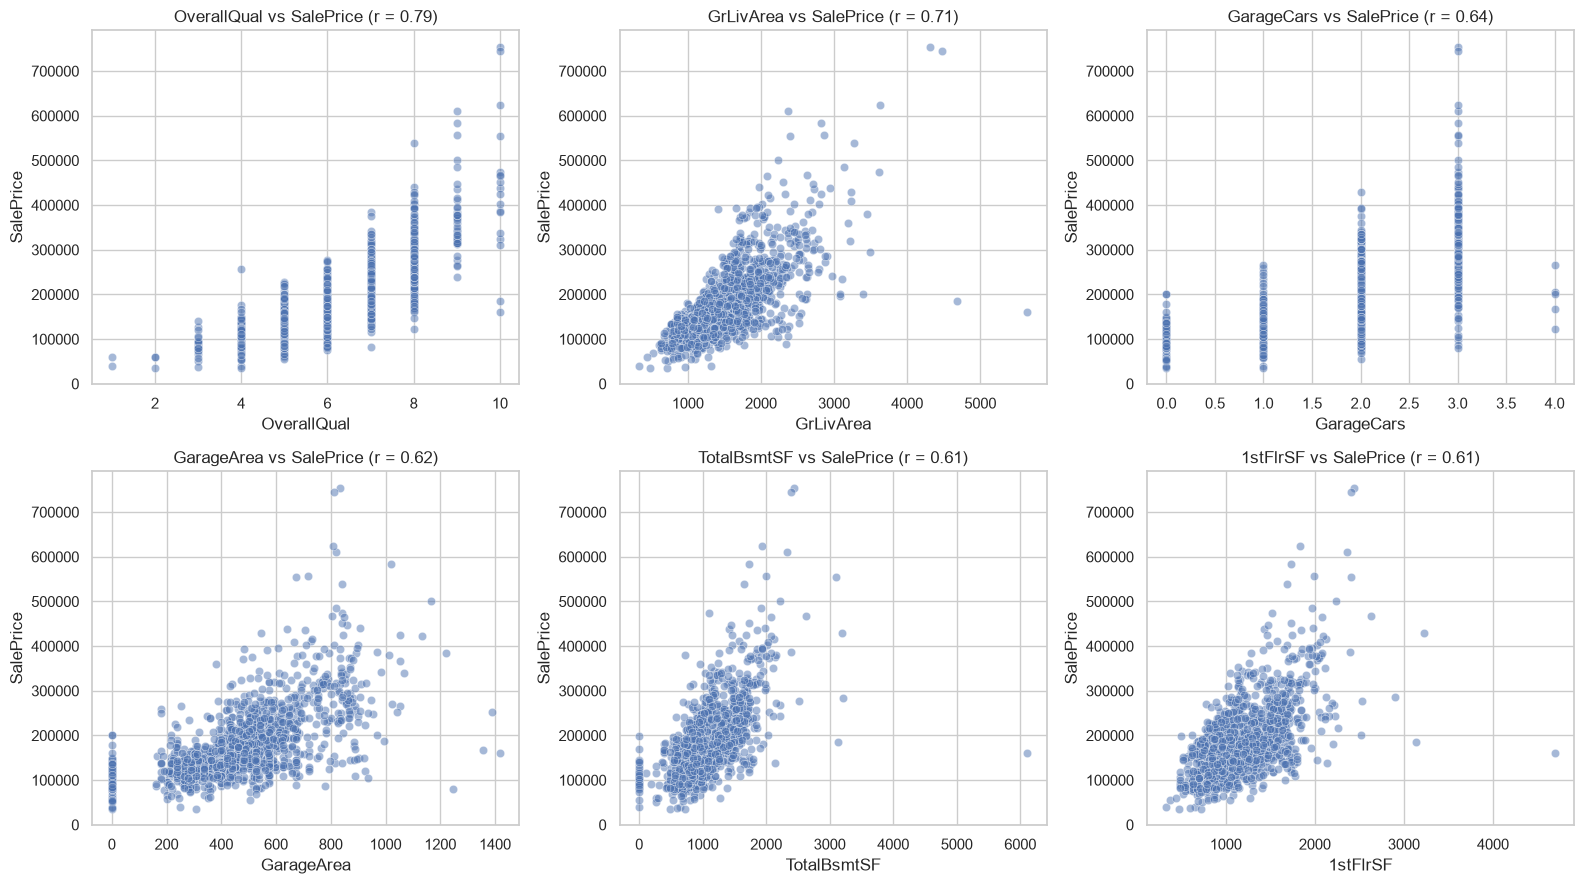

In [18]:
# ===== Scatter plot: 6 biến mạnh nhất so với giá nhà =====
# Scatter plot cho thấy độ mạnh, hình dạng, hướng của quan hệ và cả outlier (Hình 2.11)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), corr_target.head(6).index):
    sns.scatterplot(x=train[c], y=train[TARGET], ax=ax, alpha=0.5)
    ax.set_title(f"{c} vs {TARGET} (r = {corr_target[c]:.2f})")
plt.tight_layout()
plt.show()

In [19]:
# ===== Ma trận covariance của 5 biến mạnh nhất (Eq. 2.17) =====
# Covariance cho biết hướng biến thiên chung nhưng phụ thuộc đơn vị đo;
# vì vậy người ta chuẩn hóa thành correlation để so sánh được.
train[top_k[:5] + [TARGET]].cov()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,SalePrice
OverallQual,1.913,430.961,0.621,166.185,326.303,"86,904.126"
GrLivArea,430.961,"276,129.633",183.488,"52,691.984","104,861.241","29,581,866.743"
GarageCars,0.621,183.488,0.558,141.002,142.479,"38,020.181"
GarageArea,166.185,"52,691.984",141.002,"45,712.510","45,647.917","10,589,102.523"
TotalBsmtSF,326.303,"104,861.241",142.479,"45,647.917","192,462.362","21,384,416.734"
SalePrice,"86,904.126","29,581,866.743","38,020.181","10,589,102.523","21,384,416.734","6,311,111,264.297"


### 3.2 Phát hiện biến dư thừa (tương quan cao giữa các đặc trưng)

In [20]:
# ===== Tìm các cặp đặc trưng có |r| > 0.8 =====
# Sách (mục 2.6.1): nếu 2 chiều tương quan mạnh thì có thể bỏ bớt một chiều vì dư thừa
corr_feat = train[num_cols].corr()
mask = np.triu(np.ones(corr_feat.shape), k=1).astype(bool)     # chỉ lấy nửa trên, tránh trùng cặp
pairs = corr_feat.where(mask).stack()
pairs = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)

if len(pairs):
    display(pairs.to_frame("Pearson r"))
else:
    print("Không có cặp đặc trưng nào có |r| > 0.8")

,,Pearson r
GarageCars,GarageArea,0.882
YearBuilt,GarageYrBlt,0.826
GrLivArea,TotRmsAbvGrd,0.825
TotalBsmtSF,1stFlrSF,0.820


### 3.3 Pairplot (ma trận scatter)  

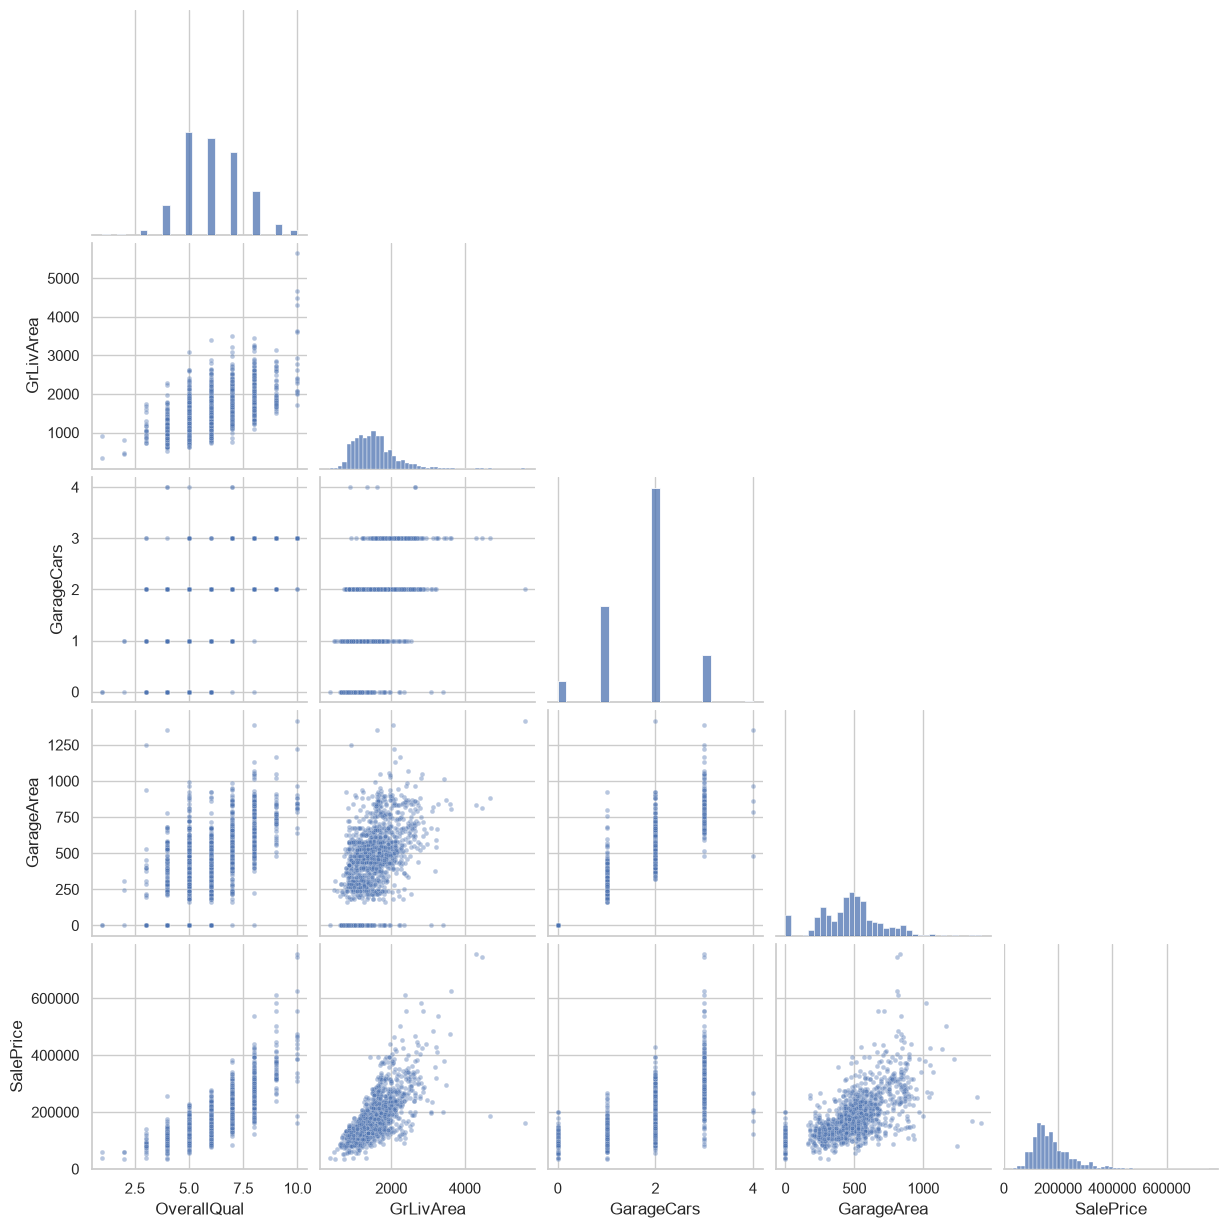

In [21]:
# ===== Pairplot cho 4 biến mạnh nhất + giá nhà =====
# Đường chéo: phân phối từng biến; các ô còn lại: scatter của từng cặp biến
sns.pairplot(train[top_k[:4] + [TARGET]].dropna(), corner=True,
             plot_kws={"alpha": 0.4, "s": 12})
plt.show()

### 3.4 Biến categorical và giá nhà (Chi-square và boxplot)

In [22]:
# ===== Kiểm định Chi-square (Mục 2.9.1) =====
# H0: biến categorical KHÔNG liên quan đến nhóm giá nhà.
# Chia giá nhà thành 4 nhóm theo tứ phân vị, rồi kiểm tra độc lập với từng biến categorical.
price_bin = pd.qcut(train[TARGET], 4, labels=False, duplicates="drop")

chi_rows = []
for c in cat_cols:
    ct = pd.crosstab(train[c].fillna("Missing"), price_bin)    # bảng tần số quan sát (observed)
    chi2, p, dof, _ = stats.chi2_contingency(ct)               # tính thống kê chi2 và p-value
    chi_rows.append({"feature": c, "chi2": chi2, "dof": dof, "p_value": p,
                     "có liên quan (p<0.05)": p < 0.05})

if chi_rows:
    chi_df = pd.DataFrame(chi_rows).set_index("feature").sort_values("chi2", ascending=False)
    display(chi_df.head(15))

,chi2,dof,p_value,có liên quan (p<0.05)
feature,,,,
Neighborhood,"1,214.306",72,0.000,True
BsmtQual,779.015,12,0.000,True
ExterQual,725.401,9,0.000,True
KitchenQual,722.058,9,0.000,True
GarageFinish,658.819,9,0.000,True
GarageType,585.582,18,0.000,True
Foundation,517.647,15,0.000,True
FireplaceQu,495.615,15,0.000,True
BsmtFinType1,400.883,18,0.000,True


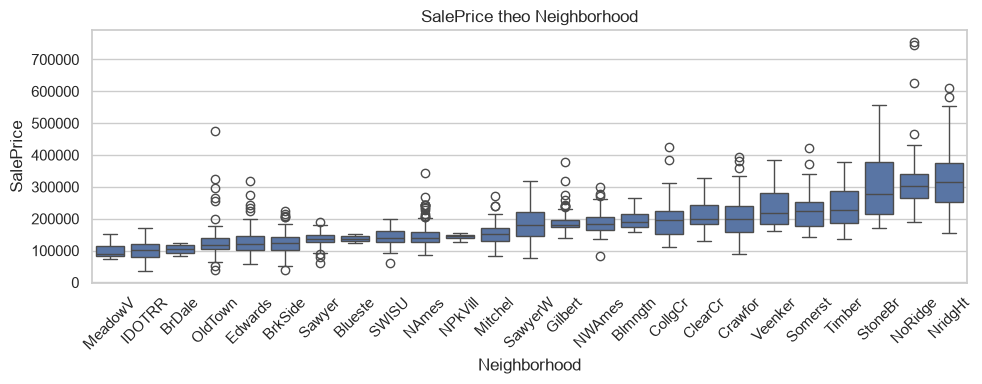

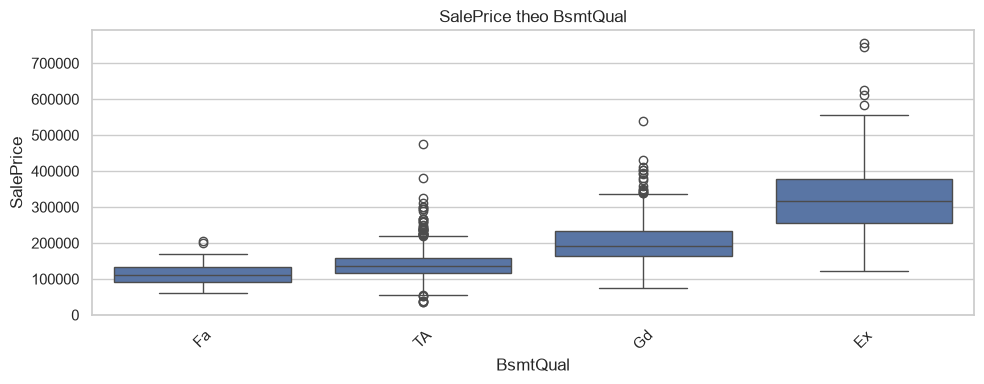

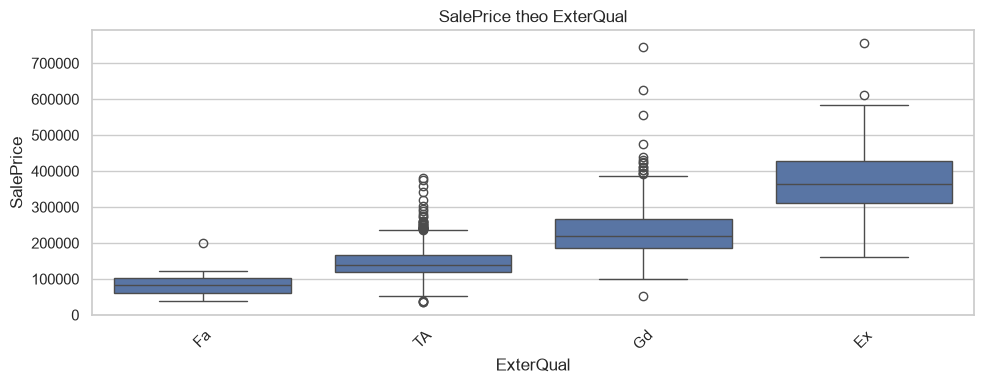

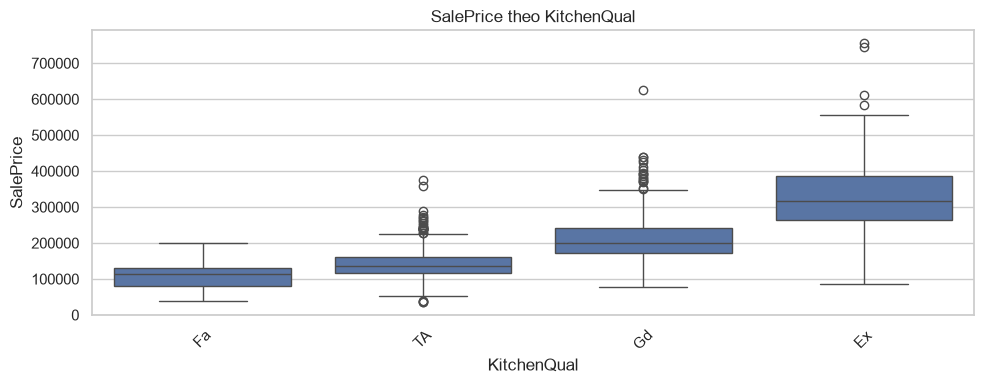

In [23]:
# ===== Boxplot giá nhà theo 4 biến categorical liên quan nhất =====
if chi_rows:
    for c in chi_df.head(4).index:
        order = train.groupby(c)[TARGET].median().sort_values().index   # sắp xếp nhóm theo median giá
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=train[c].fillna("Missing"), y=train[TARGET], order=list(order))
        plt.xticks(rotation=45)
        plt.title(f"{TARGET} theo {c}")
        plt.tight_layout()
        plt.show()

**Nhận xét (điền sau khi chạy):**
- Các biến có tương quan mạnh nhất với giá: …
- Các cặp biến dư thừa (|r| > 0.8): … → có thể giữ một biến.
- Các biến categorical liên quan nhất đến giá: …

> Nhớ rằng **tương quan không có nghĩa là nhân quả**: sách có đoạn viết bivariate analysis "deals with causes", nhưng hệ số tương quan chỉ đo mức liên hệ tuyến tính.

## 4. Giá trị thiếu và mẫu bất thường  
Sách gọi dữ liệu thực tế là **'dirty'**: thiếu giá trị (missing), không nhất quán (inconsistent),
nhiễu (noisy), ngoại lệ (outlier), trùng lặp (duplicate).

### 4.1 Giá trị thiếu

In [24]:
# ===== Thống kê giá trị thiếu ở train và test =====
test_aligned = test.reindex(columns=train.columns)      # căn cột của test giống train để so sánh
miss = pd.DataFrame({
    "số thiếu (train)": train.isna().sum(),
    "tỷ lệ (train, %)": train.isna().mean() * 100,
    "số thiếu (test)": test_aligned.isna().sum(),
    "tỷ lệ (test, %)": test_aligned.isna().mean() * 100,
})
# Chỉ giữ cột có thiếu, sắp xếp từ nhiều đến ít
miss = miss[(miss["số thiếu (train)"] > 0) | (miss["số thiếu (test)"] > 0)] \
        .sort_values("tỷ lệ (train, %)", ascending=False)

print(f"Số cột có giá trị thiếu: {len(miss)} / {train.shape[1]}")
miss

Số cột có giá trị thiếu: 35 / 81


,số thiếu (train),"tỷ lệ (train, %)",số thiếu (test),"tỷ lệ (test, %)"
PoolQC,1453,99.521,1456,99.794
MiscFeature,1406,96.301,1408,96.504
Alley,1369,93.767,1352,92.666
Fence,1179,80.753,1169,80.123
MasVnrType,872,59.726,894,61.275
FireplaceQu,690,47.260,730,50.034
LotFrontage,259,17.740,227,15.559
GarageType,81,5.548,76,5.209
GarageYrBlt,81,5.548,78,5.346
GarageFinish,81,5.548,78,5.346


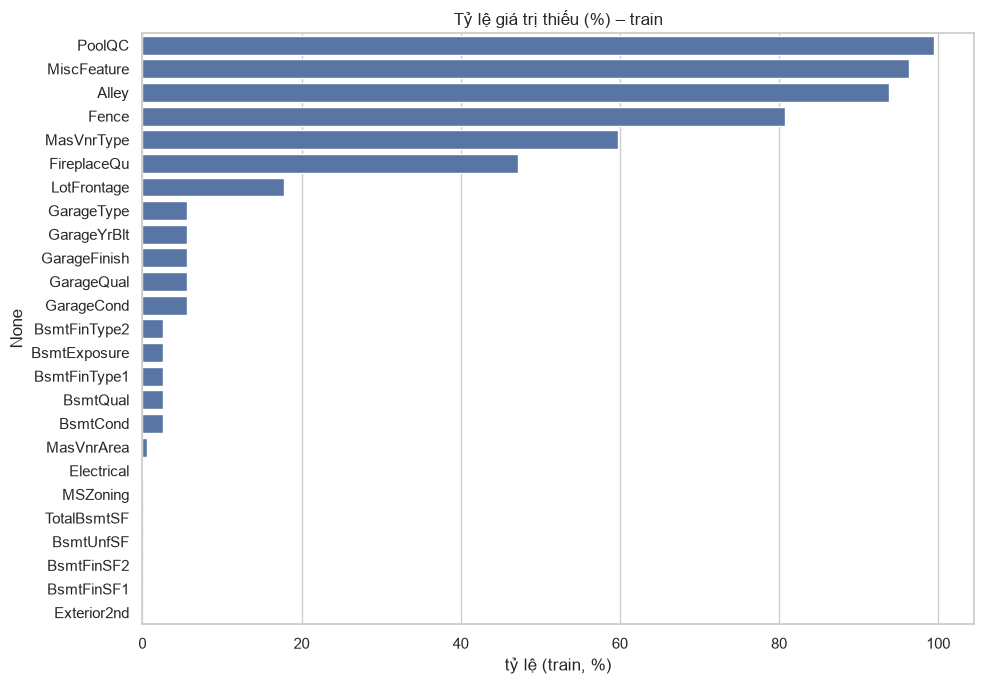

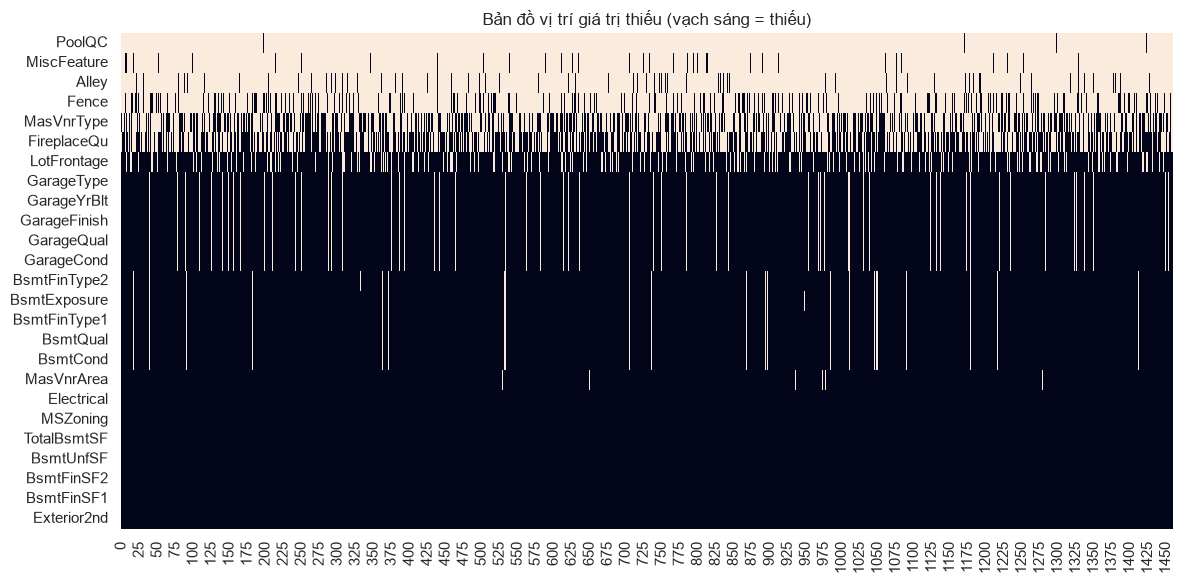

In [25]:
# ===== Trực quan hóa giá trị thiếu =====
if len(miss):
    top_miss = miss.head(25)

    # Biểu đồ cột: tỷ lệ thiếu của từng cột
    plt.figure(figsize=(10, 7))
    sns.barplot(x=top_miss["tỷ lệ (train, %)"], y=top_miss.index)
    plt.title("Tỷ lệ giá trị thiếu (%) – train")
    plt.tight_layout()
    plt.show()

    # Bản đồ vị trí thiếu: vạch sáng = ô bị thiếu. Giúp thấy các cột thiếu cùng lúc
    # (vd: các cột về garage thường cùng thiếu ở những căn nhà không có garage)
    plt.figure(figsize=(12, 6))
    sns.heatmap(train[top_miss.index].isna().T, cbar=False, yticklabels=True)
    plt.title("Bản đồ vị trí giá trị thiếu (vạch sáng = thiếu)")
    plt.tight_layout()
    plt.show()

**Cách xử lý giá trị thiếu (theo sách và thực tế):**

| Tình huống | Cách xử lý |
|---|---|
| Thiếu rất nhiều (> 40–50%) | Cân nhắc bỏ cột, hoặc hiểu là "không có tính năng đó" |
| Thiếu vì *không có* (vd: `PoolQC` thiếu = nhà không có hồ bơi) | Điền `"None"` |
| Biến numeric | Điền **median** (ít nhạy với outlier hơn mean) |
| Biến categorical | Điền **mode** hoặc `"Unknown"` |

Lưu ý: điền giá trị luôn tiềm ẩn **bias** (sai lệch), vì giá trị điền chỉ là ước lượng.

### 4.2 Mẫu bất thường và mâu thuẫn

In [26]:
# ===== Quét các dấu hiệu dữ liệu bất thường =====
issues = []

# (a) Giá trị âm ở cột không thể âm (giống ví dụ Salary = -1500 trong Table 2.1)
for c in num_cols:
    neg = (train[c] < 0).sum()
    if neg:
        issues.append(f"{c}: {neg} giá trị âm")
if (train[TARGET] <= 0).any():
    issues.append(f"{TARGET}: có giá trị <= 0")

# (b) Mâu thuẫn logic giữa các cột (giống ví dụ tuổi 5 nhưng sinh năm 1980: inconsistent data)
# Mỗi bộ: (cột A, cột B, 'A lớn hơn B là sai' hay 'A nhỏ hơn B là sai', thông báo)
logic_checks = [
    ("YearBuilt", "YrSold", "greater", "Năm xây > năm bán"),
    ("YearRemodAdd", "YearBuilt", "less", "Năm cải tạo < năm xây"),
    ("GarageYrBlt", "YearBuilt", "less", "Năm xây garage < năm xây nhà"),
]
for a, b, mode, msg in logic_checks:
    if a in train.columns and b in train.columns:
        bad = (train[a] > train[b]).sum() if mode == "greater" else (train[a] < train[b]).sum()
        if bad:
            issues.append(f"{msg}: {bad} dòng ({a} vs {b})")

# (c) Cột gần như hằng số (>95% cùng một giá trị) -> mang rất ít thông tin
for c in feature_cols:
    top_ratio = train[c].value_counts(normalize=True, dropna=False).iloc[0]
    if top_ratio > 0.95:
        issues.append(f"{c}: {top_ratio:.1%} là cùng một giá trị (ít thông tin)")

# (d) Phân phối train khác test (kiểm định Kolmogorov-Smirnov): có thể gây lệch khi dự đoán
for c in num_cols:
    if c in test.columns and test[c].notna().sum() > 30:
        ks = stats.ks_2samp(train[c].dropna(), test[c].dropna())
        if ks.pvalue < 0.01:
            issues.append(f"{c}: phân phối train và test khác nhau (KS p={ks.pvalue:.3g})")

print("\n".join(issues) if issues else "Không phát hiện bất thường rõ ràng.")

Năm xây garage < năm xây nhà: 9 dòng (GarageYrBlt vs YearBuilt)
Street: 99.6% là cùng một giá trị (ít thông tin)
Utilities: 99.9% là cùng một giá trị (ít thông tin)
Condition2: 99.0% là cùng một giá trị (ít thông tin)
RoofMatl: 98.2% là cùng một giá trị (ít thông tin)
Heating: 97.8% là cùng một giá trị (ít thông tin)
LowQualFinSF: 98.2% là cùng một giá trị (ít thông tin)
KitchenAbvGr: 95.3% là cùng một giá trị (ít thông tin)
3SsnPorch: 98.4% là cùng một giá trị (ít thông tin)
PoolArea: 99.5% là cùng một giá trị (ít thông tin)
PoolQC: 99.5% là cùng một giá trị (ít thông tin)
MiscFeature: 96.3% là cùng một giá trị (ít thông tin)
MiscVal: 96.4% là cùng một giá trị (ít thông tin)


## 5. Xác định ngoại lệ (outlier) 

Hai phương pháp trong sách:
- **IQR:** điểm nằm ngoài khoảng `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` là ngoại lệ.
- **Z-score:** `|z| > 3` là ngoại lệ có thể (hạn chế: z-score nhạy với chính outlier vì dùng mean).

In [27]:
# ===== Đếm outlier theo cả hai phương pháp cho mỗi cột numeric =====
out_rows = []
iqr_flags = pd.DataFrame(index=train.index)     # đánh dấu từng ô có phải outlier không

for c in num_cols + [TARGET]:
    s = train[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # hàng rào dưới và trên

    flag_iqr = (train[c] < low) | (train[c] > high)     # outlier theo IQR
    z = (train[c] - s.mean()) / s.std()                 # z-score (Eq. 2.2)
    flag_z = z.abs() > 3                                # outlier theo z-score

    iqr_flags[c] = flag_iqr
    out_rows.append({
        "feature": c,
        "hàng rào dưới": low,
        "hàng rào trên": high,
        "số outlier (IQR)": int(flag_iqr.sum()),
        "% outlier (IQR)": flag_iqr.mean() * 100,
        "số outlier (|z|>3)": int(flag_z.sum()),
    })

outliers = pd.DataFrame(out_rows).set_index("feature").sort_values("số outlier (IQR)", ascending=False)
outliers.head(15)

,hàng rào dưới,hàng rào trên,số outlier (IQR),% outlier (IQR),số outlier (|z|>3)
feature,,,,,
EnclosedPorch,0.000,0.000,208,14.247,51
BsmtFinSF2,0.000,0.000,167,11.438,50
OverallCond,3.500,7.500,125,8.562,28
ScreenPorch,0.000,0.000,116,7.945,55
MSSubClass,-55.000,145.000,103,7.055,30
MasVnrArea,-249.000,415.000,96,6.575,32
LotFrontage,27.500,111.500,88,6.027,12
BsmtHalfBath,0.000,0.000,82,5.616,82
OpenPorchSF,-102.000,170.000,77,5.274,27


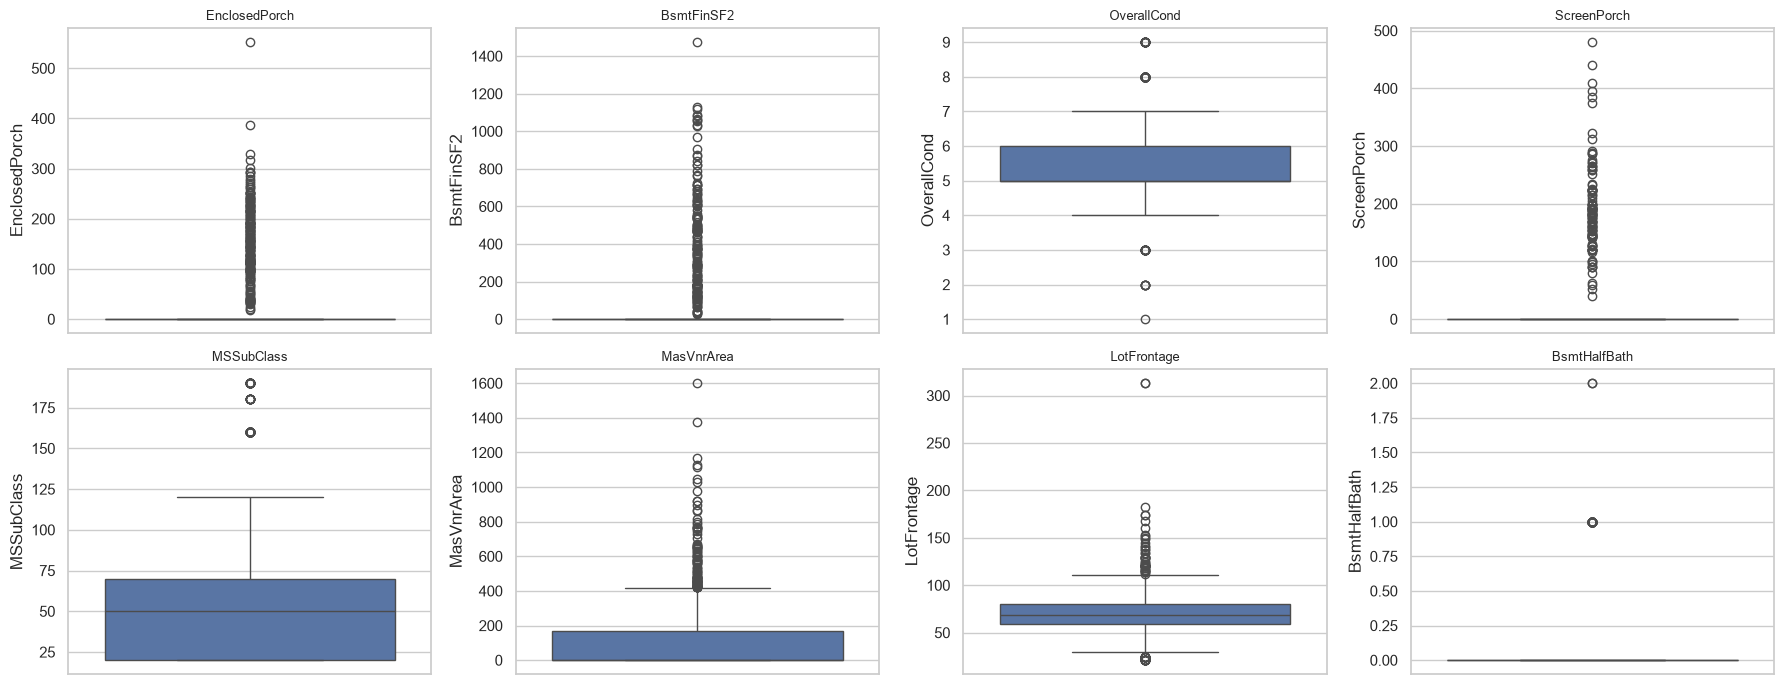

In [28]:
# ===== Boxplot của 8 biến có nhiều outlier nhất (chấm tròn ngoài râu = outlier) =====
top_out = outliers.head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), top_out):
    sns.boxplot(y=train[c], ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

In [29]:
# ===== Những dòng 'đáng ngờ': là outlier ở nhiều cột cùng lúc =====
n_flags = iqr_flags.drop(columns=TARGET).sum(axis=1)
top_rows = n_flags.sort_values(ascending=False).head(10).index
pd.DataFrame({"số cột outlier": n_flags[top_rows], TARGET: train.loc[top_rows, TARGET]})

,số cột outlier,SalePrice
1298,12,160000
523,9,184750
197,8,235000
1386,7,250000
1182,7,745000
691,7,755000
185,7,475000
1230,6,190000
803,6,582933
1173,6,200500


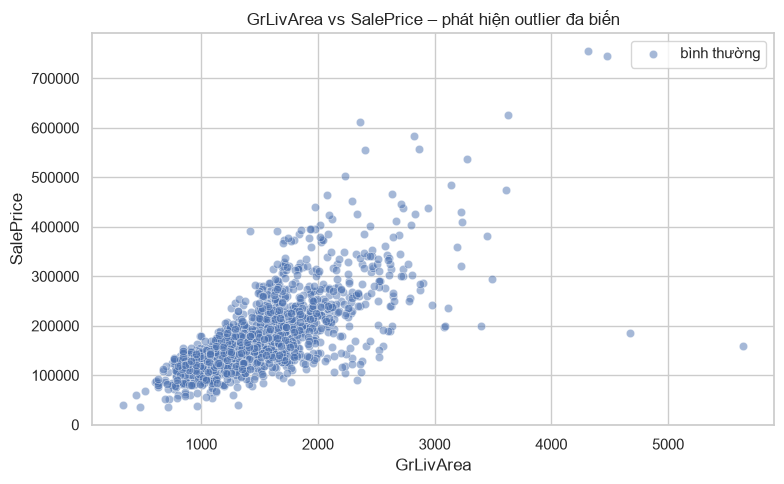

Số điểm nghi ngờ: 0


,Id,GrLivArea,SalePrice


In [30]:
# ===== Outlier đa biến: diện tích rất lớn nhưng giá lại thấp =====
# Một điểm có thể bình thường ở từng biến riêng lẻ nhưng bất thường khi xét hai biến cùng lúc.
area_col = "GrLivArea" if "GrLivArea" in train.columns else top_k[0]
hi_area = train[area_col].quantile(0.99)       # ngưỡng diện tích rất lớn (top 1%)
lo_price = train[TARGET].quantile(0.30)        # ngưỡng giá thấp (dưới 30%)
odd = train[(train[area_col] > hi_area) & (train[TARGET] < lo_price)]

plt.figure(figsize=(8, 5))
sns.scatterplot(x=train[area_col], y=train[TARGET], alpha=0.5, label="bình thường")
if len(odd):
    sns.scatterplot(x=odd[area_col], y=odd[TARGET], color="red", s=90, label="nghi ngờ")
plt.title(f"{area_col} vs {TARGET} – phát hiện outlier đa biến")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Số điểm nghi ngờ: {len(odd)}")
odd[[c for c in [ID_COL, area_col, TARGET] if c]]

**Cách xử lý ngoại lệ:**
- Outlier **có thể là dữ liệu thật** (biệt thự đắt tiền); sách cũng nhấn mạnh outlier đôi khi là thứ ta quan tâm → *không xóa mù quáng*.
- Chỉ xóa khi có dấu hiệu sai/mâu thuẫn (vd: diện tích cực lớn nhưng giá rất thấp, như các điểm đỏ ở trên).
- Có thể dùng **log transform** hoặc **winsorize** (kéo giá trị cực đoan về hàng rào IQR) thay vì xóa.

## 6. Minh họa tiền xử lý: chuẩn hóa và PCA 

Phần mở rộng (điểm cộng): áp dụng **Min-Max** , **z-score**  và **PCA** để xem có thể giảm bao nhiêu chiều.

In [31]:
# ===== Chuẩn hóa dữ liệu numeric =====
X = train[num_cols].copy()
X = X.fillna(X.median())       # PCA không chấp nhận NaN, nên điền median tạm thời

# Min-Max: đưa mọi biến về khoảng [0, 1]
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
# Z-score: đưa mọi biến về trung bình 0, độ lệch chuẩn 1
X_z = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

print(f"Min-Max: min = {X_minmax.min().min():.1f}, max = {X_minmax.max().max():.1f}")
print(f"Z-score: mean ≈ {X_z.mean().mean():.4f}, std ≈ {X_z.std().mean():.3f}")

Min-Max: min = 0.0, max = 1.0
Z-score: mean ≈ 0.0000, std ≈ 1.000


Cần 22 / 36 thành phần chính để giữ 90% phương sai của dữ liệu.


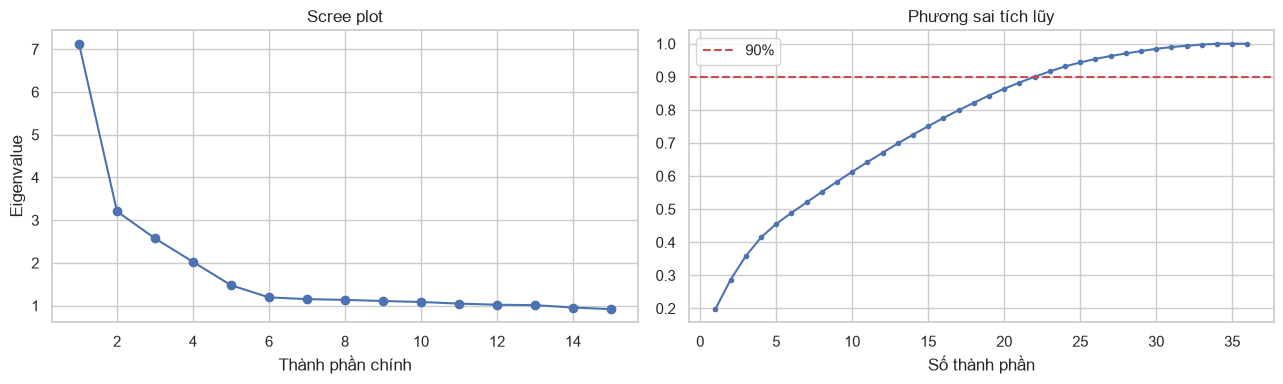

In [32]:
# ===== PCA và Scree plot (Hình 2.15) =====
# Phải chuẩn hóa trước khi PCA, nếu không biến có đơn vị lớn (diện tích) sẽ lấn át các biến khác
pca = PCA().fit(X_z)
cum = np.cumsum(pca.explained_variance_ratio_)          # phương sai tích lũy
k90 = int(np.argmax(cum >= 0.90) + 1)                   # số thành phần cần để giữ 90% phương sai
print(f"Cần {k90} / {X.shape[1]} thành phần chính để giữ 90% phương sai của dữ liệu.")

n_show = min(15, len(pca.explained_variance_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Scree plot: eigenvalue giảm dần; điểm 'khuỷu tay' cho biết nên giữ bao nhiêu thành phần
axes[0].plot(range(1, n_show + 1), pca.explained_variance_[:n_show], marker="o")
axes[0].set_title("Scree plot")
axes[0].set_xlabel("Thành phần chính")
axes[0].set_ylabel("Eigenvalue")

axes[1].plot(range(1, len(cum) + 1), cum, marker=".")
axes[1].axhline(0.9, color="r", ls="--", label="90%")
axes[1].set_title("Phương sai tích lũy")
axes[1].set_xlabel("Số thành phần")
axes[1].legend()

plt.tight_layout()
plt.show()